# Oxford-IIIT Pet: Reproducible Semantic Segmentation Experiment

This notebook implements my semester assignment as a controlled comparison:

- **Baseline:** encoder-decoder without skip connections.
- **Modified model:** the same encoder-decoder with skip fusion at the three decoder stages.

Only skip fusion changes. Dataset split, input resolution, loss, augmentation, optimiser, seed, batch size, epoch budget and evaluation procedure are shared.

## Quick Links:
Link to the dataset: [Kaggle Dataset](https://www.kaggle.com/datasets/tanlikesmath/the-oxfordiiit-pet-dataset)
GitHub: [Project](https://github.com/VibhorShukla-BHRT/Pet-Segmentation-Experiment.git)


>Note: This experiment was conducted on Kaggle with GPU T4x2. So, kindly follow the following setup guide.
## Kaggle setup 

1. Open a Kaggle Notebook and select **Add Input**.
2. Add `the-oxfordiiit-pet-dataset` (the dataset linked for this project).
3. In Notebook settings, select a GPU accelerator.
4. Run the notebook from top to bottom.

## Dataset / annotation contract

The original Oxford-IIIT Pet trimap values are mapped as follows:

| Raw trimap value | Meaning | Model class ID |
|---:|---|---:|
| 1 | Pet foreground | 0 |
| 2 | Background | 1 |
| 3 | Boundary | 2 |

No pixels are ignored. Images are resized to 128 × 128 with bilinear interpolation; masks use nearest-neighbour interpolation so the categorical labels remain integers. The direct resize changes the original aspect ratio, which is a limitation to mention in the report.

## 1. Configuration and reproducibility

In [6]:
from pathlib import Path
import os, sys, json, random, time, platform, tarfile, zipfile, textwrap, math
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

# -------------------- Experiment settings --------------------
SEED = 42
IMAGE_SIZE = 128
NUM_CLASSES = 3
CLASS_NAMES = ["pet_foreground", "background", "boundary"]
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
VAL_FRACTION = 0.20
MAX_VISUAL_SAMPLES = 8

# Kaggle paths
INPUT_ROOT = Path("/kaggle/input")
WORK_ROOT = Path("/kaggle/working")
OUTPUT_DIR = WORK_ROOT / "pet_segmentation_project"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
PRED_DIR = OUTPUT_DIR / "predictions"
for p in [OUTPUT_DIR, CHECKPOINT_DIR, PLOT_DIR, PRED_DIR]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

# ImageNet normalization is used consistently for both experiments.
IMG_MEAN = (0.485, 0.456, 0.406)
IMG_STD = (0.229, 0.224, 0.225)


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    # Deterministic settings improve repeatability; some GPU kernels may be slower.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

seed_everything()

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Output directory:", OUTPUT_DIR)

Python: 3.13.16
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda
GPU: Tesla T4
Output directory: /kaggle/working/pet_segmentation_project


## 2. Find and inspect the Kaggle dataset

In [ ]:
# Dataset discovery for the Kaggle copy of Oxford-IIIT Pet.

from pathlib import Path
import os, tarfile, urllib.request, shutil
from collections import Counter

EXTRACT_ROOT = WORK_ROOT / "pet_dataset_extracted"
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)


def safe_extract_tar(archive_path, destination):
    """Extract a tar archive while rejecting paths that escape destination."""
    destination = Path(destination).resolve()
    with tarfile.open(archive_path, "r:*") as tf:
        safe_members = []
        for member in tf.getmembers():
            target = (destination / member.name).resolve()
            if os.path.commonpath([str(destination), str(target)]) == str(destination):
                safe_members.append(member)
        tf.extractall(destination, members=safe_members)


def walk_files(root):
    """Use os.walk so the mounted Kaggle input layout is visible in diagnostics."""
    root = Path(root)
    if not root.exists():
        return
    for directory, dirnames, filenames in os.walk(root):
        dirnames.sort()
        for filename in filenames:
            path = Path(directory) / filename
            if path.is_file():
                yield path


def extract_input_archives():
    if not INPUT_ROOT.exists():
        raise FileNotFoundError(
            f"{INPUT_ROOT} does not exist. In Kaggle, use Add Input to attach the dataset."
        )
    archives = [
        p for p in walk_files(INPUT_ROOT)
        if p.name.lower().endswith((".tar", ".tar.gz", ".tgz", ".zip"))
    ]
    if not archives:
        print("No compressed archives found in /kaggle/input; checking already-extracted files.")
        return

    for archive in archives:
        marker = EXTRACT_ROOT / (archive.name.replace("/", "_") + ".done")
        if marker.exists():
            continue
        print("Extracting input archive:", archive)
        if archive.name.lower().endswith(".zip"):
            import zipfile
            with zipfile.ZipFile(archive) as zf:
                for name in zf.namelist():
                    target = (EXTRACT_ROOT / name).resolve()
                    if os.path.commonpath([str(EXTRACT_ROOT.resolve()), str(target)]) == str(EXTRACT_ROOT.resolve()):
                        zf.extract(name, EXTRACT_ROOT)
        else:
            safe_extract_tar(archive, EXTRACT_ROOT)
        marker.touch()


def scan_dataset_files():
    """Return image and trimap paths from both the Kaggle input and extracted archives."""
    search_roots = [INPUT_ROOT, EXTRACT_ROOT]
    files = []
    for root in search_roots:
        files.extend(list(walk_files(root)))

    # The images are JPG/JPEG. Ignore .mat sidecars and all mask folders.
    image_candidates = []
    mask_candidates = []
    for p in files:
        suffix = p.suffix.lower()
        parts = [part.lower() for part in p.parts]
        in_mask_folder = any(("trimap" in part or "mask" in part) for part in parts)
        if suffix in {".jpg", ".jpeg"} and not in_mask_folder:
            image_candidates.append(p)
        elif suffix == ".png" and in_mask_folder:
            mask_candidates.append(p)

    def preference(path, preferred_folder):
        parts = [part.lower() for part in path.parts]
        return (0 if preferred_folder in parts else 1, len(path.parts), str(path))

    image_by_stem = {}
    for p in sorted(image_candidates, key=lambda x: preference(x, "images")):
        image_by_stem.setdefault(p.stem.lower(), p)

    mask_by_stem = {}
    for p in sorted(mask_candidates, key=lambda x: preference(x, "trimaps")):
        mask_by_stem.setdefault(p.stem.lower(), p)

    return files, image_by_stem, mask_by_stem


extract_input_archives()
files_seen, image_by_stem, mask_by_stem = scan_dataset_files()

print("/kaggle/input exists:", INPUT_ROOT.exists())
print("Files inspected:", f"{len(files_seen):,}")
print("Image candidates (.jpg/.jpeg):", f"{len(image_by_stem):,}")
print("Trimap candidates (.png in trimap/mask folders):", f"{len(mask_by_stem):,}")

# If images cannot be found, print enough of the mounted structure to diagnose it.
if not image_by_stem:
    print("\nTop-level entries under /kaggle/input:")
    if INPUT_ROOT.exists():
        for item in sorted(INPUT_ROOT.iterdir()):
            print(" -", item, "[dir]" if item.is_dir() else "[file]")
    print("\nFirst 40 files found (with suffixes):")
    for p in files_seen[:40]:
        print(" -", p, "| suffix:", p.suffix)
    raise RuntimeError(
        "No JPG images were discovered under /kaggle/input. Check that the Kaggle dataset "
        "is attached under Notebook > Add Input, then inspect the paths printed above."
    )

if not mask_by_stem:
    annotation_archive = EXTRACT_ROOT / "annotations.tar.gz"
    annotation_urls = [
        "https://thor.robots.ox.ac.uk/datasets/pets/annotations.tar.gz",
        "https://thor.robots.ox.ac.uk/~vgg/data/pets/annotations.tar.gz",
    ]
    download_error = None
    if not annotation_archive.exists():
        for url in annotation_urls:
            try:
                print("No trimaps found. Downloading official annotations from:", url)
                request = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
                with urllib.request.urlopen(request, timeout=90) as response, open(annotation_archive, "wb") as out_file:
                    shutil.copyfileobj(response, out_file)
                # Verify that this is actually a readable tar archive before extraction.
                with tarfile.open(annotation_archive, "r:gz") as tf:
                    names = tf.getnames()
                    if not any("trimaps/" in name.lower() for name in names):
                        raise RuntimeError("Downloaded archive contains no trimaps/ directory.")
                download_error = None
                break
            except Exception as exc:
                download_error = exc
                if annotation_archive.exists():
                    annotation_archive.unlink()
                print("Download attempt failed:", repr(exc))

    if annotation_archive.exists():
        print("Extracting official segmentation annotations...")
        safe_extract_tar(annotation_archive, EXTRACT_ROOT)
        files_seen, image_by_stem, mask_by_stem = scan_dataset_files()
    elif download_error is not None:
        print("Automatic annotation download failed:", repr(download_error))

matched_stems = sorted(set(image_by_stem) & set(mask_by_stem))
records = [
    {"stem": stem, "image": image_by_stem[stem], "mask": mask_by_stem[stem]}
    for stem in matched_stems
]

print("\nFinal image count:", f"{len(image_by_stem):,}")
print("Final trimap count:", f"{len(mask_by_stem):,}")
print("Matched image/trimap pairs:", f"{len(records):,}")

if not records:
    example_images = list(image_by_stem.values())[:5]
    example_masks = list(mask_by_stem.values())[:5]
    raise RuntimeError(
        "Images were found, but no matching segmentation trimaps were found. "
        "The .mat files shown in the images folder are not pixel-level trimap masks. "
        "Enable Internet in Kaggle Notebook Settings and rerun this cell, or attach "
        "the official annotations.tar.gz (which contains annotations/trimaps/*.png) "
        "as another Kaggle input.\n"
        f"Example images: {example_images}\nExample masks: {example_masks}"
    )

print("Example image:", records[0]["image"])
print("Example trimap:", records[0]["mask"])

def find_text_file(filename):
    found = []
    for root in [INPUT_ROOT, EXTRACT_ROOT]:
        found.extend([p for p in walk_files(root) if p.name.lower() == filename.lower()])
    return sorted(found, key=lambda p: (len(p.parts), str(p)))

trainval_files = find_text_file("trainval.txt")
test_files = find_text_file("test.txt")
print("trainval.txt candidates:", trainval_files[:3])
print("test.txt candidates:", test_files[:3])


No compressed archives found in /kaggle/input; checking already-extracted files.
/kaggle/input exists: True
Files inspected: 33,261
Image candidates (.jpg/.jpeg): 7,390
Trimap candidates (.png in trimap/mask folders): 14,780

Final image count: 7,390
Final trimap count: 14,780
Matched image/trimap pairs: 7,390
Example image: /kaggle/input/datasets/tanlikesmath/the-oxfordiiit-pet-dataset/images/Abyssinian_1.jpg
Example trimap: /kaggle/working/pet_dataset_extracted/annotations/trimaps/Abyssinian_1.png
trainval.txt candidates: [PosixPath('/kaggle/working/pet_dataset_extracted/annotations/trainval.txt')]
test.txt candidates: [PosixPath('/kaggle/working/pet_dataset_extracted/annotations/test.txt')]


## 3. Build reproducible train / validation / test splits

In [8]:
record_by_stem = {r["stem"].lower(): r for r in records}


def read_official_split(txt_path):
    """Read Oxford split list. First column is the image stem; second is breed ID."""
    rows = []
    with open(txt_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split()
            stem = Path(parts[0]).stem.lower()
            breed_id = int(parts[1]) if len(parts) > 1 and parts[1].isdigit() else -1
            if stem in record_by_stem:
                rows.append((record_by_stem[stem], breed_id))
    return rows

split_mode = None
train_records, val_records, test_records = [], [], []

if trainval_files and test_files:
    trainval_rows = read_official_split(trainval_files[0])
    test_rows = read_official_split(test_files[0])
    if len(trainval_rows) > 0 and len(test_rows) > 0:
        trainval_recs = [r for r, _ in trainval_rows]
        breed_ids = [b for _, b in trainval_rows]
        indices = np.arange(len(trainval_recs))
        # Stratify by breed where available; retain deterministic seed.
        stratify_labels = breed_ids if len(set(breed_ids)) > 1 and min(Counter(breed_ids).values()) >= 2 else None
        train_idx, val_idx = train_test_split(
            indices, test_size=VAL_FRACTION, random_state=SEED, shuffle=True,
            stratify=stratify_labels
        )
        train_records = [trainval_recs[i] for i in train_idx]
        val_records = [trainval_recs[i] for i in val_idx]
        test_records = [r for r, _ in test_rows]
        split_mode = "official trainval/test lists; trainval stratified 80/20 train/validation split"

if split_mode is None:
    print("WARNING: official trainval.txt/test.txt not found or not usable.")
    print("Using a deterministic custom 80/10/10 split of matched images instead.")
    indices = np.arange(len(records))
    train_idx, temp_idx = train_test_split(indices, test_size=0.20, random_state=SEED, shuffle=True)
    val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=SEED, shuffle=True)
    train_records = [records[i] for i in train_idx]
    val_records = [records[i] for i in val_idx]
    test_records = [records[i] for i in test_idx]
    split_mode = "custom deterministic random 80/10/10 split"

# Guard against overlap and empty partitions.
train_stems = {r["stem"] for r in train_records}
val_stems = {r["stem"] for r in val_records}
test_stems = {r["stem"] for r in test_records}
assert train_stems.isdisjoint(val_stems)
assert train_stems.isdisjoint(test_stems)
assert val_stems.isdisjoint(test_stems)
assert len(train_records) and len(val_records) and len(test_records)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "images": [len(train_records), len(val_records), len(test_records)]
})
print("Split protocol:", split_mode)
display(split_summary)

# Persist the exact stem lists so the experiment can be reproduced.
with open(OUTPUT_DIR / "split_manifest.json", "w") as f:
    json.dump({
        "seed": SEED,
        "split_mode": split_mode,
        "train": sorted(train_stems),
        "validation": sorted(val_stems),
        "test": sorted(test_stems)
    }, f, indent=2)

Split protocol: official trainval/test lists; trainval stratified 80/20 train/validation split


,split,images
0,train,2944
1,validation,736
2,test,3669


## 4. Inspect images and trimap labels before training

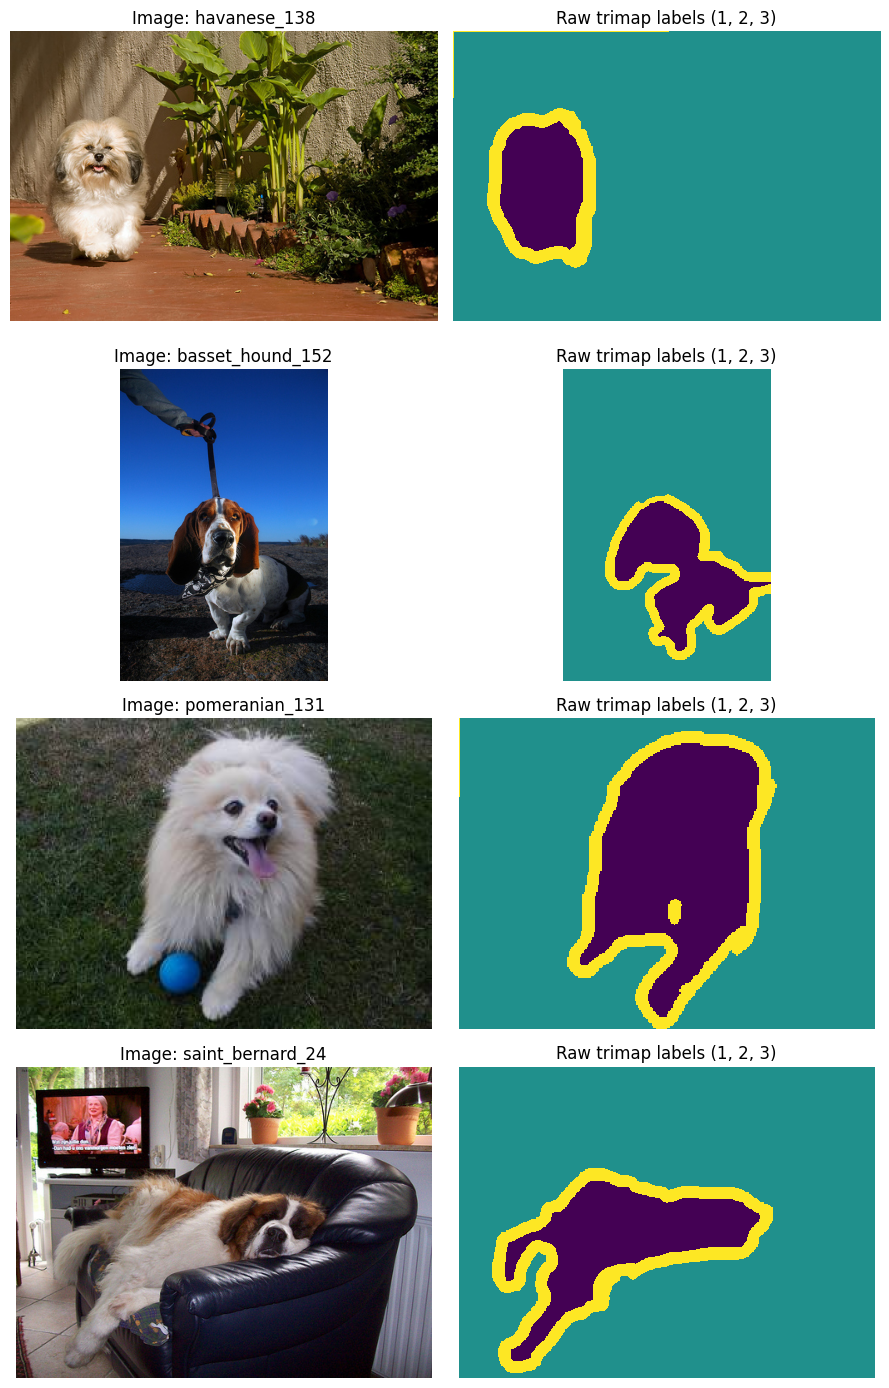

In [ ]:
# The official trimap contains integer labels 1, 2 and 3.
for rec in records[:min(100, len(records))]:
    mask = np.array(Image.open(rec["mask"]).convert("L"))
    values = set(np.unique(mask).tolist())
    if not values.issubset({1, 2, 3}):
        raise ValueError(f"Unexpected mask values {values} in {rec['mask']}; expected only 1, 2, 3.")

rng = np.random.default_rng(SEED)
show_records = [records[i] for i in rng.choice(len(records), size=min(4, len(records)), replace=False)]
fig, axes = plt.subplots(len(show_records), 2, figsize=(9, 3.5 * len(show_records)))
if len(show_records) == 1:
    axes = np.expand_dims(axes, 0)
for row, rec in enumerate(show_records):
    img = Image.open(rec["image"]).convert("RGB")
    mask = Image.open(rec["mask"]).convert("L")
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Image: {rec['stem']}")
    axes[row, 1].imshow(mask, vmin=1, vmax=3, cmap="viridis", interpolation="nearest")
    axes[row, 1].set_title("Raw trimap labels (1, 2, 3)")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Dataset, transforms and class weights

In [10]:
COLOR_JITTER = transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02)

class OxfordPetSegmentationDataset(Dataset):
    def __init__(self, samples, training=False):
        self.samples = samples
        self.training = training
        self.normalize = transforms.Normalize(IMG_MEAN, IMG_STD)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        rec = self.samples[index]
        image = Image.open(rec["image"]).convert("RGB")
        mask = Image.open(rec["mask"]).convert("L")

        # Same spatial size for image and mask, but interpolation must differ.
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE), resample=Image.Resampling.BILINEAR)
        mask = mask.resize((IMAGE_SIZE, IMAGE_SIZE), resample=Image.Resampling.NEAREST)

        mask_np = np.asarray(mask, dtype=np.uint8)
        values = np.unique(mask_np)
        if not set(values.tolist()).issubset({1, 2, 3}):
            raise ValueError(f"Unexpected trimap values {values} in {rec['mask']}")
        target = mask_np.astype(np.int64) - 1  # 1->0 pet, 2->1 background, 3->2 boundary

        if self.training:
            if random.random() < 0.5:
                image = ImageOps.mirror(image)
                target = np.fliplr(target).copy()
            image = COLOR_JITTER(image)

        image = transforms.functional.to_tensor(image)
        image = self.normalize(image)
        target = torch.from_numpy(target.copy()).long()
        return image, target

train_ds = OxfordPetSegmentationDataset(train_records, training=True)
val_ds = OxfordPetSegmentationDataset(val_records, training=False)
test_ds = OxfordPetSegmentationDataset(test_records, training=False)

# Estimate class frequencies from the training masks only.
class_counts = np.zeros(NUM_CLASSES, dtype=np.int64)
for rec in train_records:
    m = np.asarray(Image.open(rec["mask"]).convert("L"), dtype=np.uint8)
    m = m.astype(np.int64) - 1
    class_counts += np.bincount(m.reshape(-1), minlength=NUM_CLASSES)[:NUM_CLASSES]
class_freq = class_counts / class_counts.sum()
# Inverse-square-root frequency weighting moderates the imbalance without a huge weight.
class_weights_np = 1.0 / np.sqrt(np.maximum(class_freq, 1e-8))
class_weights_np = class_weights_np / class_weights_np.mean()
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)

print("Class counts (raw training pixels):", dict(zip(CLASS_NAMES, class_counts.tolist())))
print("Class frequencies:", dict(zip(CLASS_NAMES, class_freq.round(4).tolist())))
print("Cross-entropy class weights:", dict(zip(CLASS_NAMES, class_weights_np.round(4).tolist())))

loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"), worker_init_fn=seed_worker,
    generator=loader_generator, persistent_workers=False
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"), worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"), worker_init_fn=seed_worker,
    persistent_workers=(NUM_WORKERS > 0)
)

xb, yb = next(iter(train_loader))
print("Image batch:", tuple(xb.shape), xb.dtype)
print("Mask batch:", tuple(yb.shape), yb.dtype, "unique labels:", torch.unique(yb).tolist())

Class counts (raw training pixels): {'pet_foreground': 148624527, 'background': 305166241, 'boundary': 55700697}
Class frequencies: {'pet_foreground': 0.2917, 'background': 0.599, 'boundary': 0.1093}
Cross-entropy class weights: {'pet_foreground': 0.9005, 'background': 0.6285, 'boundary': 1.471}
Image batch: (32, 3, 128, 128) torch.float32
Mask batch: (32, 128, 128) torch.int64 unique labels: [0, 1, 2]


## 6. Model architectures

Both variants use the same blocks and feature widths: 32, 64, 128 and 256 channels. Each block contains two 3×3 convolutions, batch normalisation and ReLU. Max pooling halves spatial dimensions in the encoder; bilinear interpolation doubles them in the decoder.

- **Baseline:** decoder receives only the upsampled deeper feature map.
- **Skip-fusion variant:** at each level, the upsampled decoder map is concatenated with the encoder feature map of the same spatial size before the decoder block.

The output is a 3-channel per-pixel logit map. The only intended architectural difference is whether encoder features are concatenated into the decoder.

In [11]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class EncoderDecoderSegmentation(nn.Module):
    def __init__(self, use_skip_fusion=False, num_classes=NUM_CLASSES):
        super().__init__()
        self.use_skip_fusion = use_skip_fusion
        self.enc1 = ConvBlock(3, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.bottleneck = ConvBlock(128, 256)

        if use_skip_fusion:
            self.dec3 = ConvBlock(256 + 128, 128)
            self.dec2 = ConvBlock(128 + 64, 64)
            self.dec1 = ConvBlock(64 + 32, 32)
        else:
            self.dec3 = ConvBlock(256, 128)
            self.dec2 = ConvBlock(128, 64)
            self.dec1 = ConvBlock(64, 32)

        self.classifier = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)                 # 32 x H x W
        e2 = self.enc2(self.pool(e1))     # 64 x H/2 x W/2
        e3 = self.enc3(self.pool(e2))     # 128 x H/4 x W/4
        z = self.bottleneck(self.pool(e3))# 256 x H/8 x W/8

        z = F.interpolate(z, size=e3.shape[-2:], mode="bilinear", align_corners=False)
        if self.use_skip_fusion:
            z = torch.cat([z, e3], dim=1)
        z = self.dec3(z)

        z = F.interpolate(z, size=e2.shape[-2:], mode="bilinear", align_corners=False)
        if self.use_skip_fusion:
            z = torch.cat([z, e2], dim=1)
        z = self.dec2(z)

        z = F.interpolate(z, size=e1.shape[-2:], mode="bilinear", align_corners=False)
        if self.use_skip_fusion:
            z = torch.cat([z, e1], dim=1)
        z = self.dec1(z)
        return self.classifier(z)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Verify tensor dimensions and parameter counts before training.
for label, use_skips in [("Baseline", False), ("Skip fusion", True)]:
    model = EncoderDecoderSegmentation(use_skip_fusion=use_skips).to(DEVICE)
    with torch.no_grad():
        output = model(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
    print(f"{label}: output={tuple(output.shape)}, trainable_parameters={count_parameters(model):,}")

Baseline: output=(2, 3, 128, 128), trainable_parameters=1,754,819
Skip fusion: output=(2, 3, 128, 128), trainable_parameters=1,948,355


## 7. Loss, metrics and training loop

In [12]:
def confusion_matrix_update(confmat, targets, predictions, num_classes=NUM_CLASSES):
    # Rows are true classes; columns are predicted classes.
    encoded = targets.reshape(-1) * num_classes + predictions.reshape(-1)
    confmat += torch.bincount(encoded, minlength=num_classes * num_classes).reshape(num_classes, num_classes)
    return confmat


def metrics_from_confusion(confmat):
    conf = confmat.float()
    tp = torch.diag(conf)
    fp = conf.sum(dim=0) - tp
    fn = conf.sum(dim=1) - tp
    denom = tp + fp + fn
    iou = torch.where(denom > 0, tp / denom, torch.nan)
    miou = torch.nanmean(iou)
    pixel_acc = tp.sum() / conf.sum().clamp_min(1)
    return iou.detach().cpu().numpy(), float(miou.item()), float(pixel_acc.item())


criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)


def run_one_epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    running_loss = 0.0
    seen_pixels = 0
    confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=DEVICE)

    for images, masks in loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, masks)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        batch_pixels = masks.numel()
        running_loss += loss.item() * batch_pixels
        seen_pixels += batch_pixels
        predictions = logits.argmax(dim=1)
        confmat = confusion_matrix_update(confmat, masks, predictions)

    ious, miou, pixel_acc = metrics_from_confusion(confmat)
    return running_loss / max(seen_pixels, 1), miou, pixel_acc, ious


def train_model(model_name, use_skip_fusion):
    # Reset model, sampler and worker seeds before each experiment so the same
    # deterministic data order/augmentation stream is reused for the comparison.
    seed_everything(SEED)
    loader_generator.manual_seed(SEED)
    model = EncoderDecoderSegmentation(use_skip_fusion=use_skip_fusion).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    best_val_miou = -1.0
    best_epoch = -1
    history = []
    checkpoint_path = CHECKPOINT_DIR / f"{model_name}_best.pth"

    print(f"\nTraining {model_name}; parameters={count_parameters(model):,}")
    for epoch in range(1, EPOCHS + 1):
        start = time.perf_counter()
        train_loss, train_miou, train_acc, train_ious = run_one_epoch(model, train_loader, optimizer, scaler)
        val_loss, val_miou, val_acc, val_ious = run_one_epoch(model, val_loader)
        elapsed = time.perf_counter() - start

        row = {
            "model": model_name, "epoch": epoch,
            "train_loss": train_loss, "train_mIoU": train_miou,
            "val_loss": val_loss, "val_mIoU": val_miou, "val_pixel_accuracy": val_acc,
            "val_IoU_pet_foreground": val_ious[0],
            "val_IoU_background": val_ious[1],
            "val_IoU_boundary": val_ious[2],
            "epoch_seconds": elapsed, "learning_rate": optimizer.param_groups[0]["lr"]
        }
        history.append(row)
        print(
            f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f} | "
            f"val loss {val_loss:.4f} | val mIoU {val_miou:.4f} | "
            f"IoU [pet {val_ious[0]:.3f}, bg {val_ious[1]:.3f}, boundary {val_ious[2]:.3f}] | "
            f"{elapsed:.1f}s"
        )

        # Select checkpoint using validation mIoU only. Test set is not consulted here.
        if val_miou > best_val_miou:
            best_val_miou = val_miou
            best_epoch = epoch
            torch.save({
                "model_name": model_name,
                "use_skip_fusion": use_skip_fusion,
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "config": {
                    "seed": SEED, "image_size": IMAGE_SIZE, "num_classes": NUM_CLASSES,
                    "batch_size": BATCH_SIZE, "epochs_max": EPOCHS,
                    "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
                    "class_names": CLASS_NAMES, "class_weights": class_weights_np.tolist(),
                    "split_mode": split_mode
                }
            }, checkpoint_path)

    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f"{model_name}_training_log.csv", index=False)
    print(f"Best validation mIoU: {best_val_miou:.4f} at epoch {best_epoch}")
    print("Saved:", checkpoint_path)
    return history_df, checkpoint_path, best_epoch

## 8. Train the two controlled experiments


Training baseline; parameters=1,754,819


/tmp/ipykernel_49/311054927.py:62: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_49/311054927.py:37: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Epoch 01/20 | train loss 0.7871 | val loss 0.8407 | val mIoU 0.4462 | IoU [pet 0.544, bg 0.618, boundary 0.177] | 67.9s
Epoch 02/20 | train loss 0.5984 | val loss 0.5837 | val mIoU 0.5739 | IoU [pet 0.652, bg 0.769, boundary 0.300] | 15.5s
Epoch 03/20 | train loss 0.5319 | val loss 0.5761 | val mIoU 0.5772 | IoU [pet 0.653, bg 0.767, boundary 0.311] | 15.7s
Epoch 04/20 | train loss 0.4917 | val loss 0.5415 | val mIoU 0.6050 | IoU [pet 0.632, bg 0.812, boundary 0.371] | 15.6s
Epoch 05/20 | train loss 0.4591 | val loss 0.4661 | val mIoU 0.6342 | IoU [pet 0.702, bg 0.817, boundary 0.384] | 15.5s
Epoch 06/20 | train loss 0.4482 | val loss 0.4328 | val mIoU 0.6550 | IoU [pet 0.717, bg 0.840, boundary 0.408] | 15.6s
Epoch 07/20 | train loss 0.4211 | val loss 0.4389 | val mIoU 0.6497 | IoU [pet 0.726, bg 0.830, boundary 0.393] | 15.7s
Epoch 08/20 | train loss 0.4071 | val loss 0.4266 | val mIoU 0.6711 | IoU [pet 0.730, bg 0.859, boundary 0.424] | 15.4s
Epoch 09/20 | train loss 0.3910 | val lo

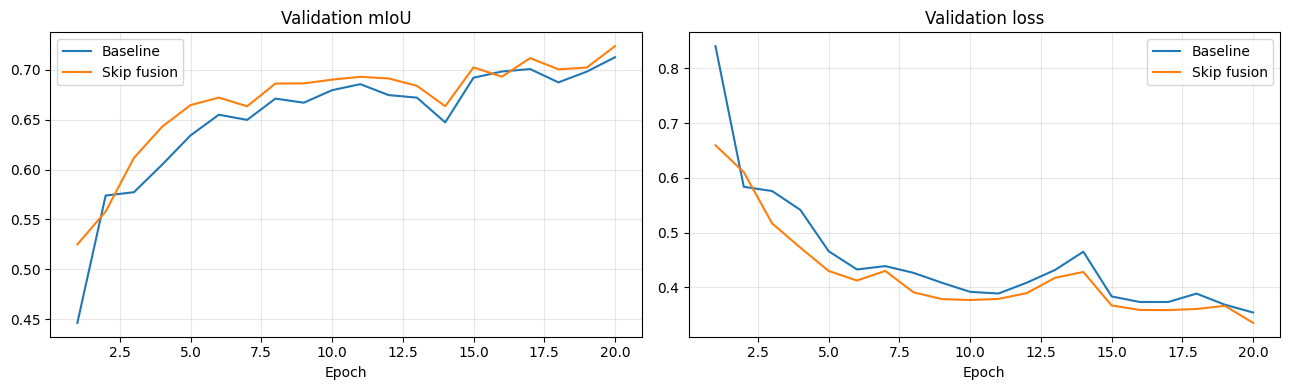

In [13]:
# Run both with the same data, augmentation, loss, optimiser, seed and epoch budget.
baseline_history, baseline_ckpt, baseline_best_epoch = train_model("baseline", use_skip_fusion=False)
skip_history, skip_ckpt, skip_best_epoch = train_model("skip_fusion", use_skip_fusion=True)

history_all = pd.concat([baseline_history, skip_history], ignore_index=True)
history_all.to_csv(OUTPUT_DIR / "combined_training_log.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, hist in [("Baseline", baseline_history), ("Skip fusion", skip_history)]:
    axes[0].plot(hist["epoch"], hist["val_mIoU"], label=name)
    axes[1].plot(hist["epoch"], hist["val_loss"], label=name)
axes[0].set_title("Validation mIoU")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "validation_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Load best validation checkpoints and evaluate the official test split

In [14]:
def load_model_from_checkpoint(path):
    # weights_only=False is explicit for compatibility with checkpoint dictionaries.
    try:
        checkpoint = torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location=DEVICE)
    model = EncoderDecoderSegmentation(use_skip_fusion=checkpoint["use_skip_fusion"]).to(DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return model, checkpoint

baseline_model, baseline_info = load_model_from_checkpoint(baseline_ckpt)
skip_model, skip_info = load_model_from_checkpoint(skip_ckpt)


def evaluate_model(model, loader):
    model.eval()
    total_loss = 0.0
    pixels = 0
    confmat = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=DEVICE)
    per_image_results = []
    with torch.inference_mode():
        for images, masks in loader:
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, masks)
            preds = logits.argmax(dim=1)
            total_loss += loss.item() * masks.numel()
            pixels += masks.numel()
            confmat = confusion_matrix_update(confmat, masks, preds)

            # Per-image mIoU is useful for finding qualitative failure cases.
            for j in range(images.size(0)):
                cm = torch.zeros((NUM_CLASSES, NUM_CLASSES), dtype=torch.int64, device=DEVICE)
                cm = confusion_matrix_update(cm, masks[j], preds[j])
                img_ious, img_miou, _ = metrics_from_confusion(cm)
                per_image_results.append({"image_iou_mean": img_miou, "class_ious": img_ious})

    ious, miou, pixel_acc = metrics_from_confusion(confmat)
    return {
        "test_loss": total_loss / max(pixels, 1),
        "mIoU": miou,
        "pixel_accuracy": pixel_acc,
        "class_IoU": ious,
        "confusion_matrix": confmat.detach().cpu().numpy(),
        "per_image": per_image_results
    }

baseline_test = evaluate_model(baseline_model, test_loader)
skip_test = evaluate_model(skip_model, test_loader)

metric_rows = []
for model_name, model, result, best_epoch in [
    ("Baseline", baseline_model, baseline_test, baseline_best_epoch),
    ("Skip fusion", skip_model, skip_test, skip_best_epoch)
]:
    row = {
        "model": model_name,
        "best_validation_epoch": best_epoch,
        "test_loss": result["test_loss"],
        "test_mIoU": result["mIoU"],
        "test_pixel_accuracy": result["pixel_accuracy"],
        "trainable_parameters": count_parameters(model),
        "test_IoU_pet_foreground": result["class_IoU"][0],
        "test_IoU_background": result["class_IoU"][1],
        "test_IoU_boundary": result["class_IoU"][2],
    }
    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
display(metrics_df)

# Save confusion matrices and per-image scores for reproducible analysis.
for name, result in [("baseline", baseline_test), ("skip_fusion", skip_test)]:
    np.save(OUTPUT_DIR / f"{name}_test_confusion_matrix.npy", result["confusion_matrix"])
    pd.DataFrame({
        "test_index": np.arange(len(result["per_image"])),
        "image_mean_IoU": [x["image_iou_mean"] for x in result["per_image"]],
        "IoU_pet_foreground": [x["class_ious"][0] for x in result["per_image"]],
        "IoU_background": [x["class_ious"][1] for x in result["per_image"]],
        "IoU_boundary": [x["class_ious"][2] for x in result["per_image"]],
    }).to_csv(OUTPUT_DIR / f"{name}_per_image_test_scores.csv", index=False)

,model,best_validation_epoch,test_loss,test_mIoU,test_pixel_accuracy,trainable_parameters,test_IoU_pet_foreground,test_IoU_background,test_IoU_boundary
0,Baseline,20,0.355173,0.723460,0.885443,1754819,0.783389,0.883714,0.503277
1,Skip fusion,20,0.339440,0.733669,0.890226,1948355,0.790789,0.886627,0.523589


## 10. Parameter count and measured inference latency

In [15]:
def measure_latency_ms(model, device=DEVICE, warmup=20, runs=100):
    model.eval()
    sample = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
    with torch.inference_mode():
        for _ in range(warmup):
            _ = model(sample)
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(runs):
            _ = model(sample)
        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
    return (elapsed / runs) * 1000

latency_rows = []
for name, model in [("Baseline", baseline_model), ("Skip fusion", skip_model)]:
    latency = measure_latency_ms(baseline_model if name == "Baseline" else skip_model)
    latency_rows.append({
        "model": name,
        "parameters": count_parameters(model),
        "latency_ms_per_image": latency,
        "device": str(DEVICE),
        "input_shape": f"1x3x{IMAGE_SIZE}x{IMAGE_SIZE}",
        "warmup_runs": 20,
        "timed_runs": 100,
        "measurement_scope": "model forward pass only; excludes file I/O and preprocessing"
    })

latency_df = pd.DataFrame(latency_rows)
latency_df.to_csv(OUTPUT_DIR / "latency_measurements.csv", index=False)
display(latency_df)

comparison_df = metrics_df.merge(
    latency_df[["model", "latency_ms_per_image"]], on="model", how="left"
)
comparison_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
display(comparison_df)

,model,parameters,latency_ms_per_image,device,input_shape,warmup_runs,timed_runs,measurement_scope
0,Baseline,1754819,3.046924,cuda,1x3x128x128,20,100,model forward pass only; excludes file I/O and...
1,Skip fusion,1948355,4.254630,cuda,1x3x128x128,20,100,model forward pass only; excludes file I/O and...


,model,best_validation_epoch,test_loss,test_mIoU,test_pixel_accuracy,trainable_parameters,test_IoU_pet_foreground,test_IoU_background,test_IoU_boundary,latency_ms_per_image
0,Baseline,20,0.355173,0.723460,0.885443,1754819,0.783389,0.883714,0.503277,3.046924
1,Skip fusion,20,0.339440,0.733669,0.890226,1948355,0.790789,0.886627,0.523589,4.254630


## 11. Qualitative predictions and failure examples

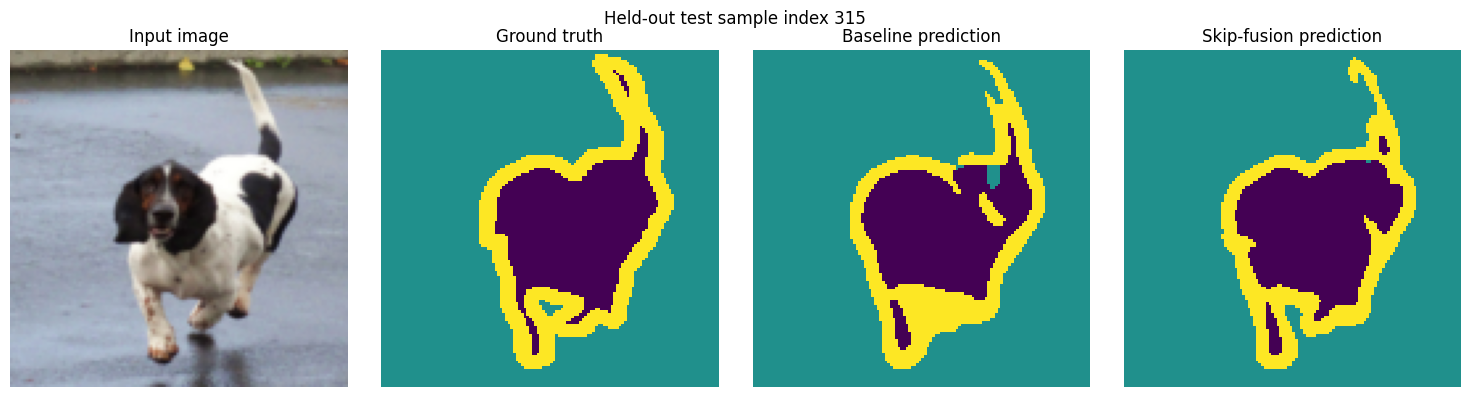

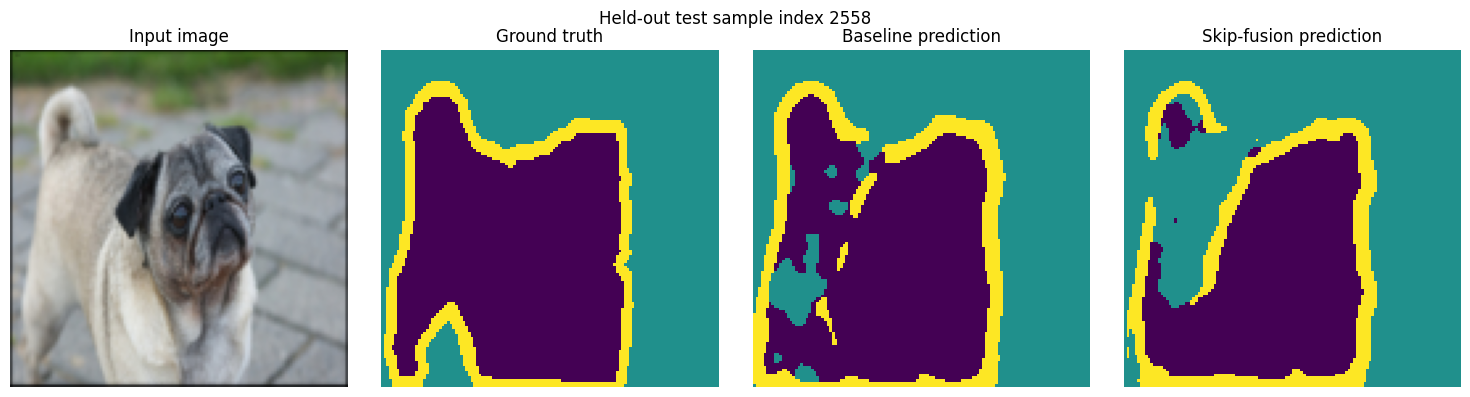

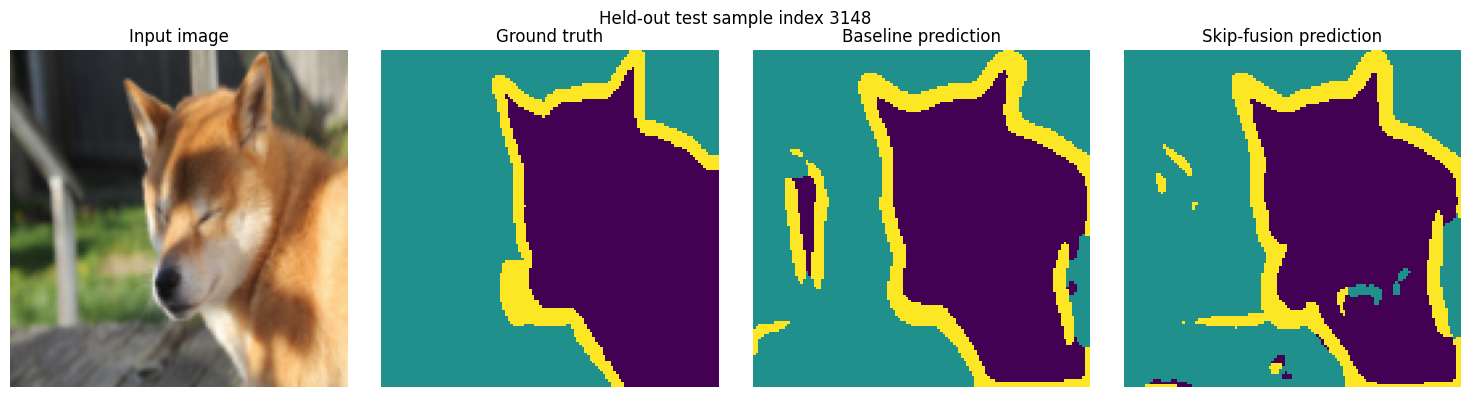

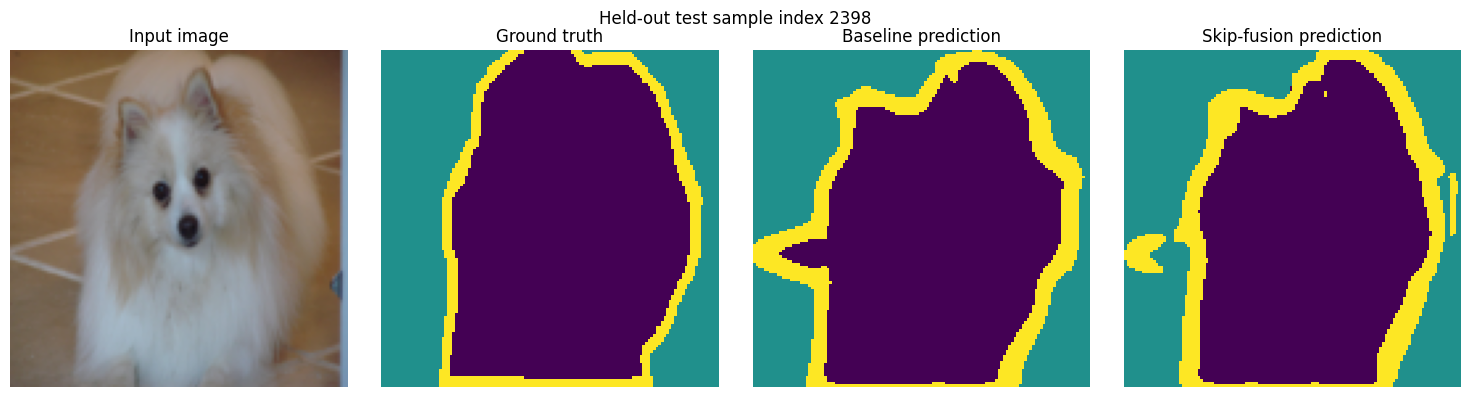

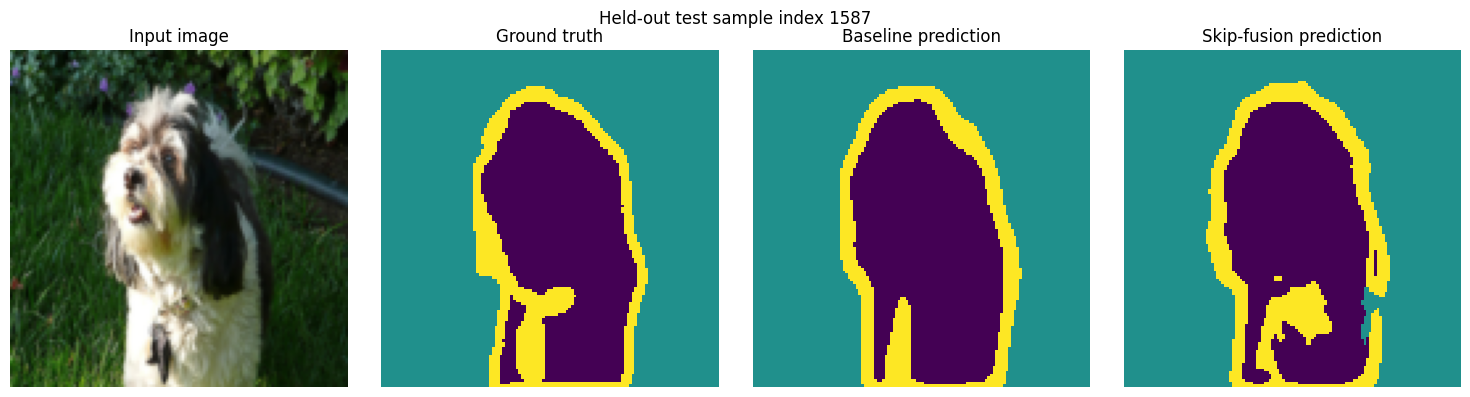

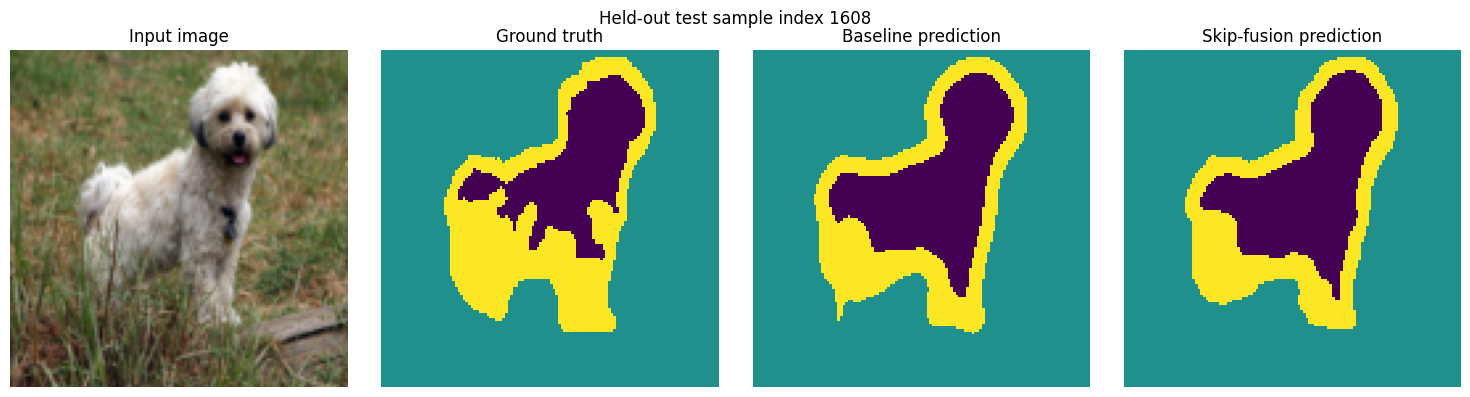

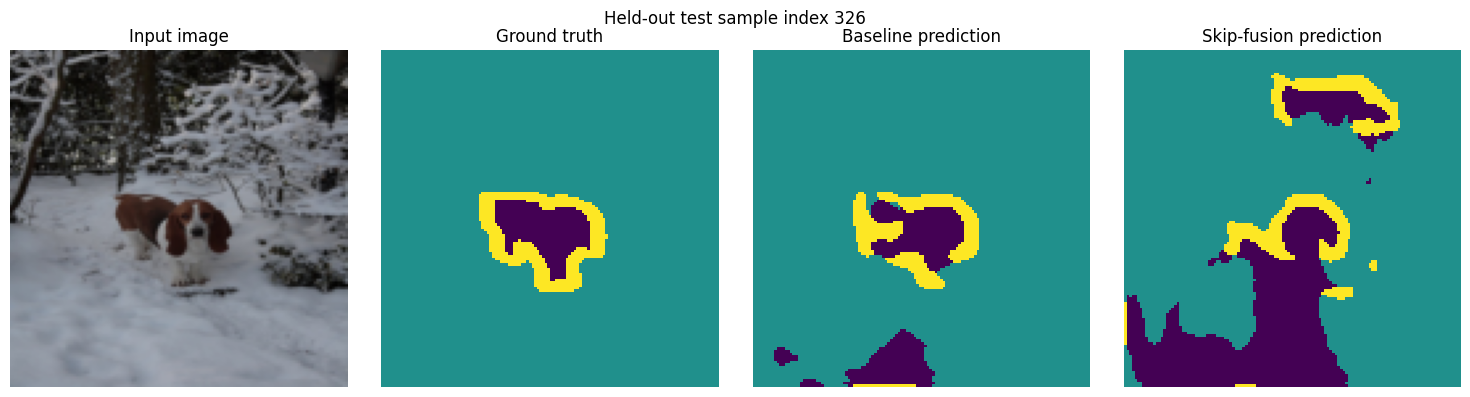

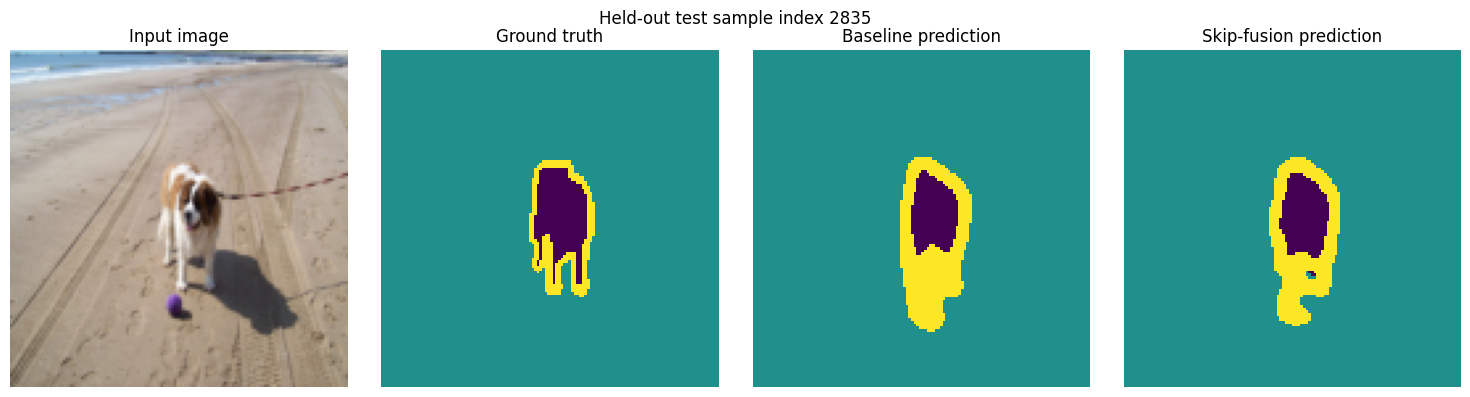


Lowest per-image mIoU examples for baseline:
[(1858, 0.016), (1690, 0.1037), (2292, 0.1511), (2302, 0.1525), (1093, 0.1554)]


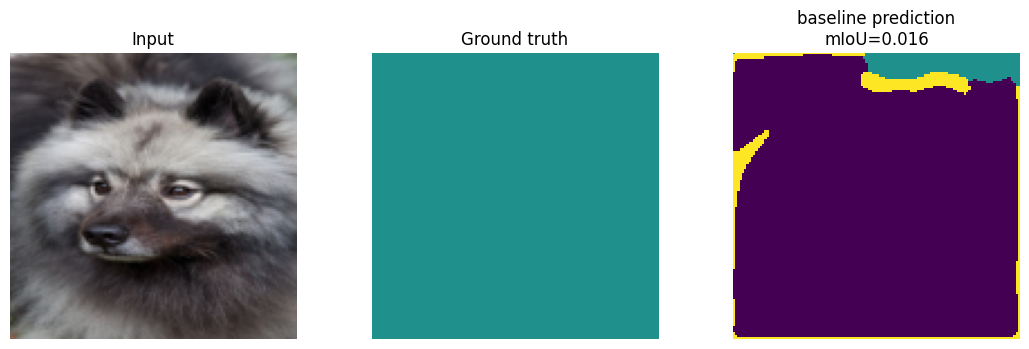

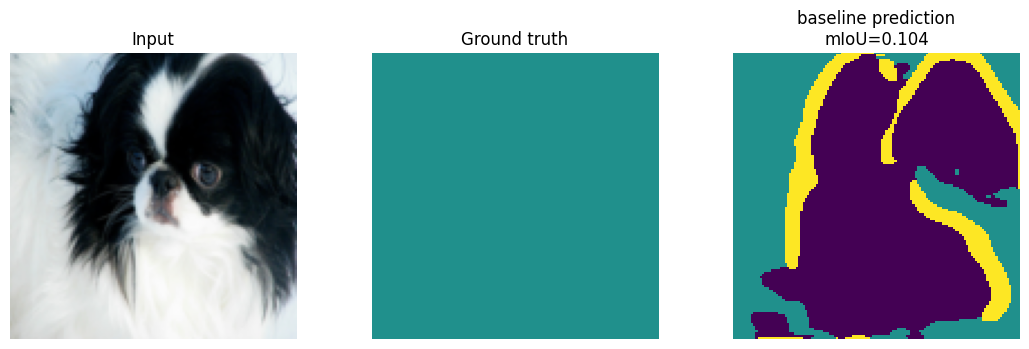

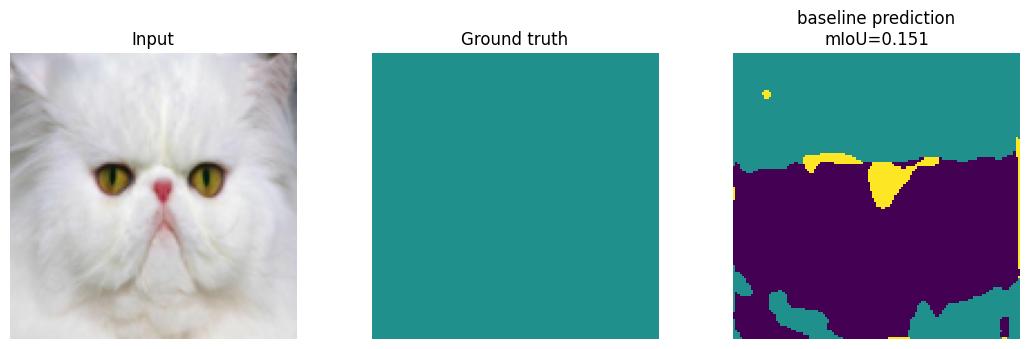


Lowest per-image mIoU examples for skip_fusion:
[(1858, 0.0207), (1690, 0.1056), (2292, 0.1195), (1093, 0.162), (2302, 0.1648)]


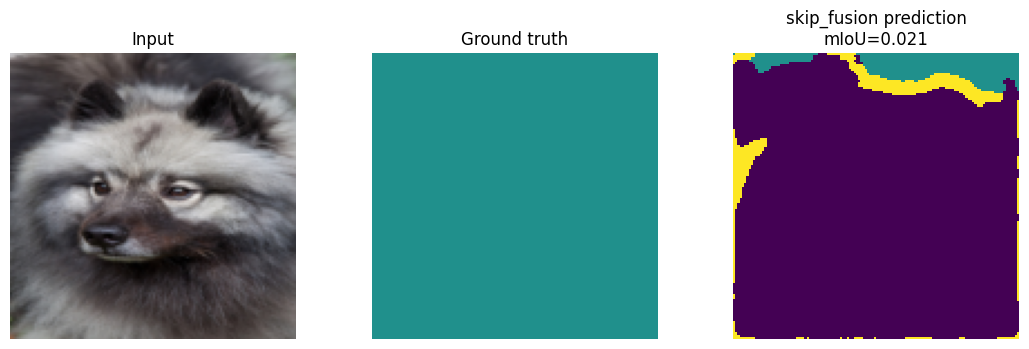

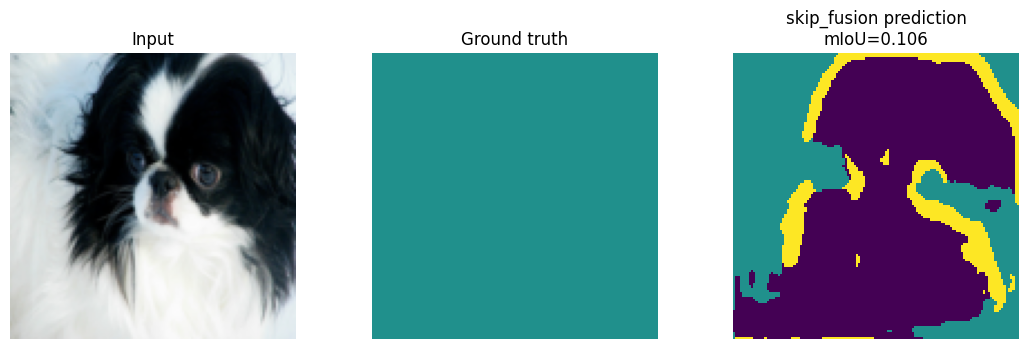

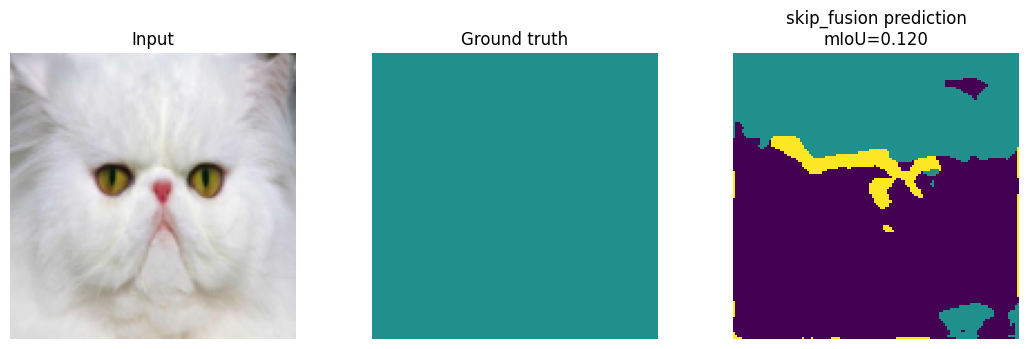

In [16]:
def denormalize(img_tensor):
    mean = torch.tensor(IMG_MEAN).view(3, 1, 1)
    std = torch.tensor(IMG_STD).view(3, 1, 1)
    x = img_tensor.detach().cpu() * std + mean
    return x.clamp(0, 1).permute(1, 2, 0).numpy()


def predict_mask(model, image_tensor):
    with torch.inference_mode():
        logits = model(image_tensor.unsqueeze(0).to(DEVICE))
        return logits.argmax(dim=1).squeeze(0).cpu().numpy()

# Create a qualitative panel using a reproducible selection from the held-out test set.
vis_rng = np.random.default_rng(SEED)
vis_indices = vis_rng.choice(len(test_ds), size=min(MAX_VISUAL_SAMPLES, len(test_ds)), replace=False)

for idx in vis_indices:
    image_tensor, gt = test_ds[int(idx)]
    baseline_pred = predict_mask(baseline_model, image_tensor)
    skip_pred = predict_mask(skip_model, image_tensor)
    image_rgb = denormalize(image_tensor)

    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    axes[0].imshow(image_rgb); axes[0].set_title("Input image")
    axes[1].imshow(gt.numpy(), vmin=0, vmax=2, cmap="viridis", interpolation="nearest"); axes[1].set_title("Ground truth")
    axes[2].imshow(baseline_pred, vmin=0, vmax=2, cmap="viridis", interpolation="nearest"); axes[2].set_title("Baseline prediction")
    axes[3].imshow(skip_pred, vmin=0, vmax=2, cmap="viridis", interpolation="nearest"); axes[3].set_title("Skip-fusion prediction")
    for ax in axes: ax.axis("off")
    plt.suptitle(f"Held-out test sample index {idx}")
    plt.tight_layout()
    plt.savefig(PRED_DIR / f"test_sample_{idx:04d}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Automatically identify the lowest-scoring test examples for each model.
# These are candidates for the report's failure analysis; inspect them before explaining why they failed.
for name, result in [("baseline", baseline_test), ("skip_fusion", skip_test)]:
    scores = np.array([x["image_iou_mean"] for x in result["per_image"]])
    worst = np.argsort(scores)[:min(5, len(scores))]
    print(f"\nLowest per-image mIoU examples for {name}:")
    print([(int(i), round(float(scores[i]), 4)) for i in worst])
    for idx in worst[:3]:
        image_tensor, gt = test_ds[int(idx)]
        pred = predict_mask(baseline_model if name == "baseline" else skip_model, image_tensor)
        fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
        axes[0].imshow(denormalize(image_tensor)); axes[0].set_title("Input")
        axes[1].imshow(gt.numpy(), vmin=0, vmax=2, cmap="viridis", interpolation="nearest"); axes[1].set_title("Ground truth")
        axes[2].imshow(pred, vmin=0, vmax=2, cmap="viridis", interpolation="nearest"); axes[2].set_title(f"{name} prediction\nmIoU={scores[idx]:.3f}")
        for ax in axes: ax.axis("off")
        plt.tight_layout()
        plt.savefig(PRED_DIR / f"{name}_failure_{int(idx):04d}.png", dpi=150, bbox_inches="tight")
        plt.show()

## 12. Export experiment configuration, environment and report-ready artifacts

In [17]:
experiment_config = {
    "project": "Oxford-IIIT Pet semantic segmentation controlled experiment",
    "dataset": "Oxford-IIIT Pet",
    "dataset_source": "https://www.kaggle.com/datasets/tanlikesmath/the-oxfordiiit-pet-dataset",
    "official_dataset_reference": "https://www.robots.ox.ac.uk/~vgg/data/pets/",
    "split_protocol": split_mode,
    "seed": SEED,
    "image_size": [IMAGE_SIZE, IMAGE_SIZE],
    "mask_interpolation": "nearest",
    "image_interpolation": "bilinear",
    "mask_mapping": {"1": "pet_foreground (class 0)", "2": "background (class 1)", "3": "boundary (class 2)"},
    "ignored_label": None,
    "augmentation": ["random horizontal flip p=0.5 (joint image/mask)", "ColorJitter on training images only"],
    "normalization_mean": list(IMG_MEAN),
    "normalization_std": list(IMG_STD),
    "model_common_architecture": "3-level encoder, two-convolution ConvBlocks, widths 32/64/128, 256-channel bottleneck, bilinear decoder",
    "controlled_change": "skip fusion: concatenate matching encoder features into decoder at 1/4, 1/2 and full resolution",
    "loss": "class-weighted CrossEntropyLoss; inverse-square-root pixel-frequency weights computed on training masks only",
    "optimizer": "AdamW",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "batch_size": BATCH_SIZE,
    "epoch_budget": EPOCHS,
    "checkpoint_selection": "highest validation mIoU",
    "evaluation_metrics": ["per-class IoU", "mIoU", "pixel accuracy", "parameter count", "forward-pass latency"],
    "latency_protocol": "batch size 1, fixed 128x128 input, 20 warmup and 100 timed forward passes; preprocessing excluded",
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}
with open(OUTPUT_DIR / "experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

# A README template with the actual run settings, but without inventing interpretation.
readme = f"""# Oxford-IIIT Pet Semantic Segmentation\n\n## Experiments\n- Baseline encoder-decoder without skip connections.\n- Same encoder-decoder with skip fusion.\n\n## Dataset\nOxford-IIIT Pet trimap segmentation. Raw mask values: 1=pet, 2=background, 3=boundary.\nSource: {experiment_config['dataset_source']}\nOfficial page: {experiment_config['official_dataset_reference']}\n\n## Reproducibility settings\n- Seed: {SEED}\n- Split: {split_mode}\n- Input: {IMAGE_SIZE}x{IMAGE_SIZE}\n- Batch size: {BATCH_SIZE}; epochs: {EPOCHS}\n- Optimizer: AdamW, lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY}\n- Loss: class-weighted CrossEntropyLoss\n- Best checkpoint: highest validation mIoU\n\n## Outputs\n- `test_metrics.csv`: final held-out test metrics, including per-class IoU and mIoU\n- `latency_measurements.csv`: measured model forward latency conditions\n- `model_comparison.csv`: combined comparison table\n- `*_training_log.csv`: epoch-wise logs\n- `split_manifest.json`: exact train/validation/test image stems\n- `experiment_config.json`: experiment configuration and environment\n- `checkpoints/`: best validation checkpoints (large; do not commit unless needed)\n- `plots/` and `predictions/`: plots and qualitative examples\n\n## Important\nDo not treat the test metrics as validation results. Checkpoint selection uses validation mIoU; the test set is evaluated after training. Latency numbers are hardware-dependent and exclude image loading and preprocessing.\n\n## Reference\nParkhi, O. M., Vedaldi, A., Zisserman, A., and Jawahar, C. V. (2012). Cats and Dogs. IEEE Conference on Computer Vision and Pattern Recognition (CVPR).\n"""
(OUTPUT_DIR / "README.md").write_text(readme, encoding="utf-8")

# Save a compact plain-text file with the final comparison for easy report drafting.
with open(OUTPUT_DIR / "report_results_summary.txt", "w") as f:
    f.write("EXPERIMENT RESULTS - COPY ONLY VALUES FROM THIS FILE INTO YOUR OWN ANALYSIS\n")
    f.write("\nSplit protocol: " + split_mode + "\n")
    f.write("\nTEST METRICS\n")
    f.write(metrics_df.to_string(index=False))
    f.write("\n\nLATENCY\n")
    f.write(latency_df.to_string(index=False))
    f.write("\n\nInterpret the numbers yourself after inspecting the qualitative examples and failure cases.\n")

print("\nAll artifacts saved under:", OUTPUT_DIR)
print("Main files:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file():
        print(" -", p.relative_to(OUTPUT_DIR), f"({p.stat().st_size / 1024:.1f} KB)")


All artifacts saved under: /kaggle/working/pet_segmentation_project
Main files:
 - README.md (1.6 KB)
 - baseline_per_image_test_scores.csv (196.1 KB)
 - baseline_test_confusion_matrix.npy (0.2 KB)
 - baseline_training_log.csv (3.3 KB)
 - checkpoints/baseline_best.pth (6895.4 KB)
 - checkpoints/skip_fusion_best.pth (7651.7 KB)
 - combined_training_log.csv (6.6 KB)
 - experiment_config.json (1.8 KB)
 - latency_measurements.csv (0.3 KB)
 - model_comparison.csv (0.4 KB)
 - plots/validation_curves.png (94.1 KB)
 - predictions/baseline_failure_1690.png (68.2 KB)
 - predictions/baseline_failure_1858.png (69.1 KB)
 - predictions/baseline_failure_2292.png (58.8 KB)
 - predictions/skip_fusion_failure_1690.png (69.1 KB)
 - predictions/skip_fusion_failure_1858.png (70.0 KB)
 - predictions/skip_fusion_failure_2292.png (60.0 KB)
 - predictions/test_sample_0315.png (80.2 KB)
 - predictions/test_sample_0326.png (81.5 KB)
 - predictions/test_sample_1587.png (87.0 KB)
 - predictions/test_sample_1608.p

In [25]:
!zip -r proj.zip pet_segmentation_project/

  adding: pet_segmentation_project/ (stored 0%)
  adding: pet_segmentation_project/experiment_config.json (deflated 48%)
  adding: pet_segmentation_project/baseline_training_log.csv (deflated 53%)
  adding: pet_segmentation_project/model_comparison.csv (deflated 36%)
  adding: pet_segmentation_project/skip_fusion_test_confusion_matrix.npy (deflated 43%)
  adding: pet_segmentation_project/checkpoints/ (stored 0%)
  adding: pet_segmentation_project/checkpoints/skip_fusion_best.pth (deflated 7%)
  adding: pet_segmentation_project/checkpoints/baseline_best.pth (deflated 7%)
  adding: pet_segmentation_project/split_manifest.json (deflated 89%)
  adding: pet_segmentation_project/baseline_per_image_test_scores.csv (deflated 56%)
  adding: pet_segmentation_project/plots/ (stored 0%)
  adding: pet_segmentation_project/plots/validation_curves.png (deflated 8%)
  adding: pet_segmentation_project/report_results_summary.txt (deflated 54%)
  adding: pet_segmentation_project/predictions/ (stored 0%)


In [ ]:
!zip -r proj.zip pet_dataset_extracted

  adding: pet_dataset_extracted/ (stored 0%)
  adding: pet_dataset_extracted/annotations.tar.gz (deflated 0%)
  adding: pet_dataset_extracted/annotations/ (stored 0%)
  adding: pet_dataset_extracted/annotations/trainval.txt (deflated 89%)
  adding: pet_dataset_extracted/annotations/._trimaps (deflated 36%)
  adding: pet_dataset_extracted/annotations/list.txt (deflated 89%)
  adding: pet_dataset_extracted/annotations/trimaps/ (stored 0%)
  adding: pet_dataset_extracted/annotations/trimaps/._beagle_53.png (deflated 36%)
  adding: pet_dataset_extracted/annotations/trimaps/Ragdoll_199.png (deflated 1%)
  adding: pet_dataset_extracted/annotations/trimaps/._Bombay_68.png (deflated 36%)
  adding: pet_dataset_extracted/annotations/trimaps/._beagle_57.png (deflated 36%)
  adding: pet_dataset_extracted/annotations/trimaps/scottish_terrier_186.png (deflated 16%)
  adding: pet_dataset_extracted/annotations/trimaps/._pug_158.png (deflated 36%)
  adding: pet_dataset_extracted/annotations/trimaps/pug